In [111]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [112]:
df = pd.read_csv("healthcare-dataset-stroke-data.csv")

In [113]:
df.head(10).T

,0,1,2,3,4,5,6,7,8,9
id,9046,51676,31112,60182,1665,56669,53882,10434,27419,60491
gender,Male,Female,Male,Female,Female,Male,Male,Female,Female,Female
age,67.0,61.0,80.0,49.0,79.0,81.0,74.0,69.0,59.0,78.0
hypertension,0,0,0,0,1,0,1,0,0,0
heart_disease,1,0,1,0,0,0,1,0,0,0
ever_married,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes
work_type,Private,Self-employed,Private,Private,Self-employed,Private,Private,Private,Private,Private
Residence_type,Urban,Rural,Rural,Urban,Rural,Urban,Rural,Urban,Rural,Urban
avg_glucose_level,228.69,202.21,105.92,171.23,174.12,186.21,70.09,94.39,76.15,58.57
bmi,36.6,NaN,32.5,34.4,24.0,29.0,27.4,22.8,NaN,24.2


In [114]:
df = df.drop(columns="id")

In [115]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   str    
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   str    
 5   work_type          5110 non-null   str    
 6   Residence_type     5110 non-null   str    
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                4909 non-null   float64
 9   smoking_status     5110 non-null   str    
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(3), str(5)
memory usage: 594.7 KB


In [116]:
df.shape

(5110, 11)

In [117]:
df.describe()

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


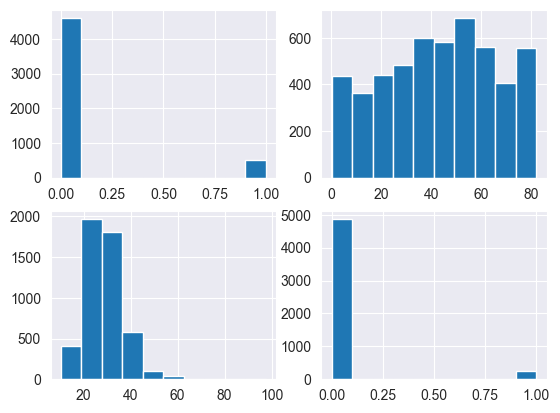

In [118]:
plt.subplot(2,2,1)
plt.hist(x="hypertension",data=df)
plt.subplot(2,2,2)
plt.hist(x="age",data=df)
plt.subplot(2,2,3)
plt.hist(x="bmi",data=df)
plt.subplot(2,2,4)
plt.hist(x="stroke",data=df)
plt.show()

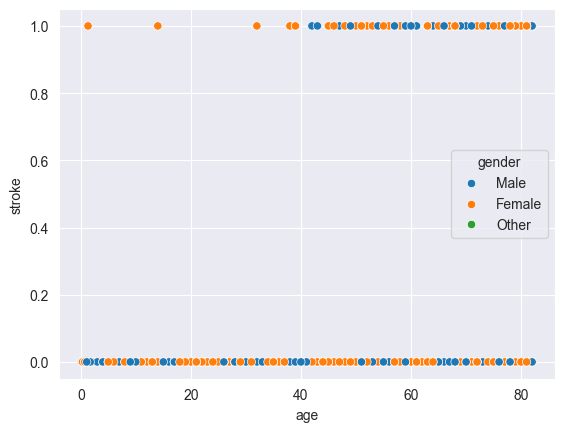

In [119]:
sns.scatterplot(x="age",y="stroke",data=df,hue="gender")
plt.show()

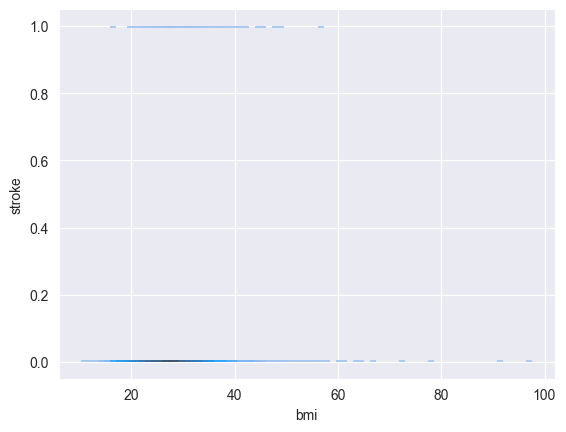

In [120]:
sns.histplot(x="bmi",y="stroke",data=df)
plt.show()

In [121]:
CategoricC = df.select_dtypes(include=["str","object"]).columns

In [122]:
CategoricC

Index(['gender', 'ever_married', 'work_type', 'Residence_type',
       'smoking_status'],
      dtype='str')

In [123]:
NumericC = df.select_dtypes(include=["float64","int64"]).columns

In [124]:
NumericC

Index(['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi',
       'stroke'],
      dtype='str')

In [125]:
numCorr = df[NumericC].corr()

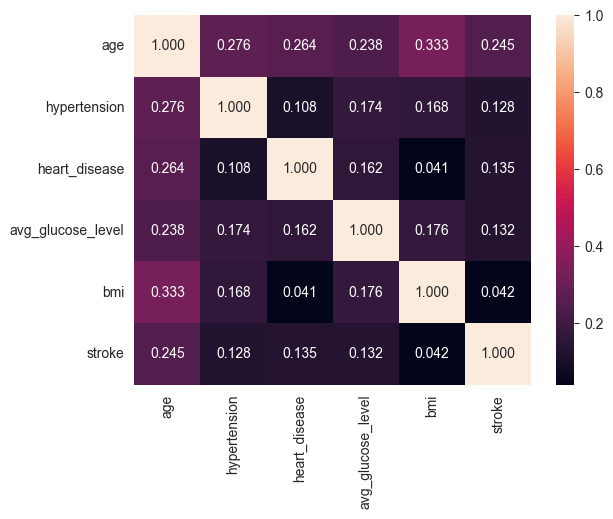

In [126]:
sns.heatmap(numCorr, annot=True, fmt=".3f")
plt.show()

In [127]:
df.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [128]:
df["stroke"].value_counts()

stroke
0    4861
1     249
Name: count, dtype: int64

In [129]:
df[df["stroke"] == 1].groupby("bmi").size().sum()

np.int64(209)

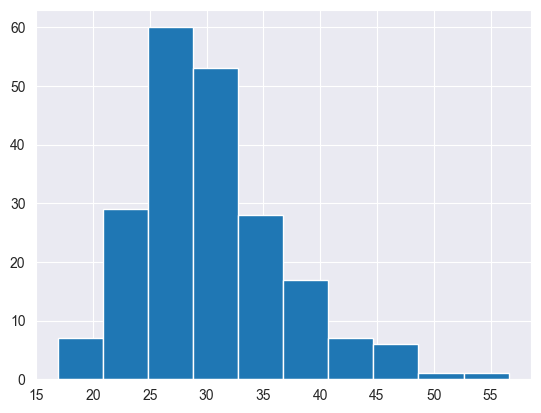

In [130]:
plt.hist(data=df[df["stroke"] == 1], x="bmi")
plt.show()

In [131]:
df["bmi"] = df["bmi"].fillna(df["bmi"].median())

In [132]:
df.isnull().sum()

gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

In [133]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.1,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [134]:
df["smoking_status"].value_counts()

smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64

In [135]:
z = ["gender","ever_married","work_type","Residence_type","smoking_status"]

In [136]:
for col in z:

    print(col)
    print("***********************")
    x = df[col].value_counts()
    print(x)
    print("\n---------------------\n")

gender
***********************
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

---------------------

ever_married
***********************
ever_married
Yes    3353
No     1757
Name: count, dtype: int64

---------------------

work_type
***********************
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

---------------------

Residence_type
***********************
Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64

---------------------

smoking_status
***********************
smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64

---------------------



In [137]:
df["work_type"] = df["work_type"].replace({"children": "Not_working", "Never_worked": "Not_working"})

In [138]:
df = df[df["gender"] != "Other"].reset_index(drop=True)

In [139]:
df = pd.get_dummies(df, drop_first=True, dtype=int)

In [140]:
df.head()

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Male,ever_married_Yes,work_type_Not_working,work_type_Private,work_type_Self-employed,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.6,1,1,1,0,1,0,1,1,0,0
1,61.0,0,0,202.21,28.1,1,0,1,0,0,1,0,0,1,0
2,80.0,0,1,105.92,32.5,1,1,1,0,1,0,0,0,1,0
3,49.0,0,0,171.23,34.4,1,0,1,0,1,0,1,0,0,1
4,79.0,1,0,174.12,24.0,1,0,1,0,0,1,0,0,1,0
